In [171]:
import serial
import numpy as np
import matplotlib.pyplot as plt
import time

In [107]:
import serial.tools.list_ports as port_list
ports = list(port_list.comports())
for p in ports: print(p)

COM1 - Port de communication (COM1)
COM9 - USB Serial Port (COM9)


In [108]:
serial_add = 'COM9'

In [111]:
ser = serial.Serial(serial_add,baudrate=9600,bytesize=8, parity='N',stopbits=1,timeout=.05)

In [112]:
ser.write(b'*IDN?\r')
l=ser.readline()
response=l.decode('ascii', errors='replace')
print(response)

KEITHLEY INSTRUMENTS INC.,MODEL 2000,4416118,B01  /A02  


In [113]:
ser.write(b'DISP:ENAB OFF\r')#ENAB OFF/ON(turn on, off the display) , *IDN? (affiche les caractéristique)

14

In [180]:
ser.write(b'DISP:ENAB ON\r')#ENAB OFF/ON(turn on, off the display) , *IDN? (affiche les caractéristique)

13

In [138]:
ser.write(b"DISP:TEXT:STAT ON\r")

18

In [116]:
ser.write(b"DISP:TEXT:DATA 'TEST 12'\r")

25

In [142]:
ser.write(b"DISP:TEXT:STAT OFF\r")

19

In [143]:

ser.write(b"MEAS?\n")

6

In [181]:
#methode pourrie mais fonctionne si dt pas trop petit
def aquis(dt,N):
    tab = np.zeros(N)
    t = np.arange(N)*dt
    for i in range(N):
        ser.write(b"READ?\n")
        time.sleep(dt)
        tab[i] = float(ser.readline().decode())
    return tab, t

In [182]:
data = aquis(0.5,100)
V = data[0]
t = data[1]

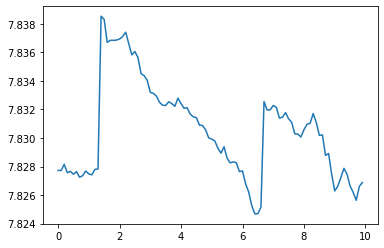

In [174]:
plt.plot(t,V)

In [212]:
dt = 0.1
NPLC = dt/0.2
t =np.arange(100)*dt

ser.write(b"CONF:VOLT:DC\n")
ser.write(b"VOLT:DC:NPLC 0.5\n")
ser.write(b'TRIG:SOURCE IMM\n')
ser.write(b'SAMP:COUNT 100\n')
ser.write(b'TRIG:COUNT 1\n')
ser.write(b'INIT\n')
ser.write(b'*OPC?\n')
#time.sleep(t+1)
ser.write(b"FETCh?\n")
time.sleep(1)
raw = ser.readline().decode().strip()
raw = raw.replace('1\r','')
data = np.array([float(x) for x in raw.split(",")])

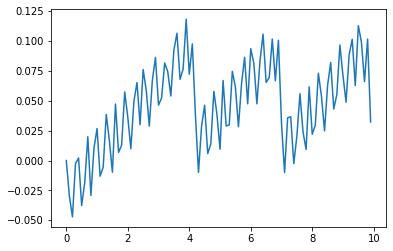

In [213]:
plt.plot(t, data)